# **Brain Tumor MRI Image Classification**  -  Custom CNN + Transfer Learning

##### **Project Type**    - Classification (Deep Learning / Medical Imaging)
##### **Contribution**    - Individual
##### **Team Member 1 -**  Yash

# **Project Summary -**

Brain tumors are among the most time-critical conditions in radiology. A radiologist has to look at many MRI slices, decide whether a tumor is present, and identify its type, because the treatment path differs for each type. This project builds a deep-learning system that classifies a brain MRI image into one of the tumor categories present in the dataset, and wraps the best model in a Streamlit web application so that a user can upload an MRI image and instantly see the predicted class together with a confidence score.

The work follows the complete computer-vision lifecycle. First, the dataset is scanned and audited: number of classes, class balance, image resolution, colour mode, corrupt files and exact duplicate images are all checked. Duplicate images that appear in more than one split are removed so that the test score is not inflated by data leakage. The data is then arranged into training, validation and test sets (the dataset's own split is used when available, otherwise a stratified 70/15/15 split is created).

Six exploratory charts explain the data: class distribution, distribution per split, sample images, image-size distribution, pixel-intensity distribution and the effect of augmentation. Every chart answers why it was chosen, what it shows, and what it means for the business.

For preprocessing, every image is resized to 224x224 and normalised to a model-friendly pixel range, and the training images are augmented on the fly with flips, rotation, zoom, shift and brightness changes to improve generalisation. Class weights are computed to handle any class imbalance.

Four models are trained and compared: (1) a custom CNN built from scratch with convolution blocks, batch normalisation, max pooling and dropout; and three ImageNet-pretrained backbones, (2) MobileNetV2, (3) EfficientNetB0 and (4) InceptionV3, each with a new classification head. The pretrained models are trained in two phases: first only the new head is trained, then the top layers of the backbone are unfrozen and fine-tuned with a very small learning rate. EarlyStopping, ModelCheckpoint and ReduceLROnPlateau callbacks monitor validation loss and save the best weights of every model as an .h5 file.

All models are evaluated on the untouched test set using accuracy, precision, recall, F1-score, confusion matrix and training-history plots, and are also compared on parameter count, file size and inference time. The final model is selected on validation performance, with special attention to per-class recall, because in a medical setting missing a tumor is far more costly than a false alarm.

The best model is saved as best_model.h5 together with class_names.json, reloaded for a sanity check on unseen images, and served through a Streamlit app (app.py) that shows the predicted tumor type and confidence for any uploaded MRI image. The tool is meant as an assistive second opinion for radiologists and triage workflows, not as a replacement for clinical judgement.

# **GitHub Link -**

https://github.com/yashbobade1904/Brain-Tumor-MRI-Classification

# **Problem Statement**

**Develop a deep learning solution that classifies brain MRI images into tumor categories. Build a custom CNN from scratch, improve performance with transfer learning on pretrained models, compare all models with proper evaluation metrics, and deploy the best one in a Streamlit web app that predicts the tumor type and confidence from an uploaded MRI image.**

# **General Guidelines** : -
1. Code is structured, commented and written so that the notebook runs top-to-bottom in one go.
2. Image-classification adaptation of the template: the tabular-only parts of the template (missing-value imputation, outlier treatment, categorical encoding, text preprocessing, correlation heatmap / pair plot, GridSearchCV) do not apply to MRI images. They are replaced by the equivalent image steps: dataset audit, resizing/normalisation, augmentation, class weighting, fine-tuning and callbacks.
3. Every chart answers: why this chart, what insight, what business impact.
4. Every model answers: what the model is, how it performed, and what tuning was done.

# ***Let's Begin !***

## ***0. Setup & Configuration***

### Import Libraries

In [9]:
# Import Libraries
import os, sys, json, time, random, shutil, hashlib, pathlib, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

from sklearn.model_selection import train_test_split
from sklearn.metrics import (classification_report, confusion_matrix,
                             accuracy_score, precision_recall_fscore_support)
from sklearn.utils.class_weight import compute_class_weight

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

# ---- Reproducibility ----
SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

# ---- Global configuration (all tunable values in one place) ----
IMG_SIZE        = (224, 224)   # input size for every model
BATCH_SIZE      = 32
EPOCHS          = int(os.environ.get("BT_EPOCHS", 20))      # phase-1 epochs (EarlyStopping will stop earlier)
FINE_TUNE_EPOCHS = int(os.environ.get("BT_FT_EPOCHS", 10))  # phase-2 (fine-tuning) epochs
FINE_TUNE_AT    = 40           # number of top backbone layers to unfreeze
WEIGHTS         = os.environ.get("BT_WEIGHTS", "imagenet")  # "imagenet" for real runs
MODEL_DIR       = "models"
os.makedirs(MODEL_DIR, exist_ok=True)

print("TensorFlow:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


### Dataset Loading

The dataset is the *Brain Tumor MRI Multi-Class Dataset* shared on Google Drive. In Colab, add the shared folder as a shortcut to **My Drive** (right-click -> *Add shortcut to Drive*), then set `DEFAULT_DIR` below to its path. On a local machine, download the folder and point `DEFAULT_DIR` to it.

The loader below walks through the folder and works with any of these layouts: `train/ test/` (and optionally `val/`) with one sub-folder per class, or a flat folder with one sub-folder per class.

In [10]:
# ---- Dataset location ----
if not os.path.isdir("/content/Tumour"):
    os.system("unzip -q -o /content/dataset.zip -d /content/")
DEFAULT_DIR = "/content/Tumour"

DATA_DIR = os.environ.get("BT_DATA_DIR", DEFAULT_DIR)
assert os.path.isdir(DATA_DIR), f"Dataset folder not found: {DATA_DIR}  ->  update DEFAULT_DIR above."

IMG_EXT = (".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff")
SPLIT_ALIASES = {"train": "train", "training": "train",
                 "val": "val", "valid": "val", "validation": "val",
                 "test": "test", "testing": "test"}

# Walk the folder: class = parent folder name, split = a parent folder named train/val/test (if any)
rows = []
for root, _, files in os.walk(DATA_DIR):
    for f in files:
        if f.lower().endswith(IMG_EXT):
            p = pathlib.Path(root, f)
            parts = p.relative_to(DATA_DIR).parts[:-1]
            split = None
            for part in parts:
                if part.lower() in SPLIT_ALIASES:
                    split = SPLIT_ALIASES[part.lower()]
            rows.append((str(p), p.parent.name, split))

df = pd.DataFrame(rows, columns=["path", "label", "split"])
assert len(df) > 0, "No images found - check DATA_DIR and the folder structure."
print(f"Found {len(df)} images")

Found 2443 images


In [11]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## ***1. Know Your Data***

### Dataset First View

In [12]:
# Dataset First Look
df.head()

,path,label,split
0,/content/Tumour/test/no_tumor/Tr-no_0354_jpg.r...,no_tumor,test
1,/content/Tumour/test/no_tumor/Tr-no_0032_jpg.r...,no_tumor,test
2,/content/Tumour/test/no_tumor/Tr-no_0172_jpg.r...,no_tumor,test
3,/content/Tumour/test/no_tumor/Tr-no_0213_jpg.r...,no_tumor,test
4,/content/Tumour/test/no_tumor/Tr-no_0315_jpg.r...,no_tumor,test


### Dataset Rows & Columns count

In [13]:
# Dataset Rows & Columns count
print("Rows (images):", df.shape[0])
print("Columns      :", df.shape[1])
print("Number of classes:", df["label"].nunique(), "->", sorted(df["label"].unique()))

Rows (images): 2443
Columns      : 3
Number of classes: 4 -> ['glioma', 'meningioma', 'no_tumor', 'pituitary']


### Dataset Information

In [14]:
# Dataset Info
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2443 entries, 0 to 2442
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   path    2443 non-null   object
 1   label   2443 non-null   object
 2   split   2443 non-null   object
dtypes: object(3)
memory usage: 57.4+ KB


#### Duplicate Values

In [15]:
# Exact duplicate images (same file content) are found with an MD5 hash of the file bytes.
def file_md5(path, chunk=1 << 20):
    h = hashlib.md5()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(chunk), b""):
            h.update(block)
    return h.hexdigest()

df["md5"] = df["path"].apply(file_md5)
dup_mask = df.duplicated("md5", keep=False)
print("Images that have at least one exact duplicate:", int(dup_mask.sum()))
print("Redundant copies (would be removed)          :", int(df.duplicated("md5").sum()))

# Duplicates that sit in BOTH train and test would leak information -> check that explicitly
if df["split"].notna().any():
    grp = df[dup_mask].groupby("md5")["split"].nunique()
    print("Duplicate groups spread over more than one split:", int((grp > 1).sum()))

Images that have at least one exact duplicate: 0
Redundant copies (would be removed)          : 0
Duplicate groups spread over more than one split: 0


#### Missing Values/Null Values

In [16]:
# Missing / corrupt check. For images the "missing value" equivalent is an unreadable file.
def image_meta(path):
    try:
        with Image.open(path) as im:
            w, h = im.size
            mode = im.mode
            im.verify()                # raises if the file is truncated / corrupt
        return w, h, mode, False
    except Exception:
        return np.nan, np.nan, None, True

meta = df["path"].apply(image_meta)
df[["width", "height", "mode", "corrupt"]] = pd.DataFrame(meta.tolist(), index=df.index)

print("Null values per column:\n", df.isnull().sum(), "\n")
print("Corrupt / unreadable images:", int(df["corrupt"].sum()))

Null values per column:
 path       0
label      0
split      0
md5        0
width      0
height     0
mode       0
corrupt    0
dtype: int64 

Corrupt / unreadable images: 0


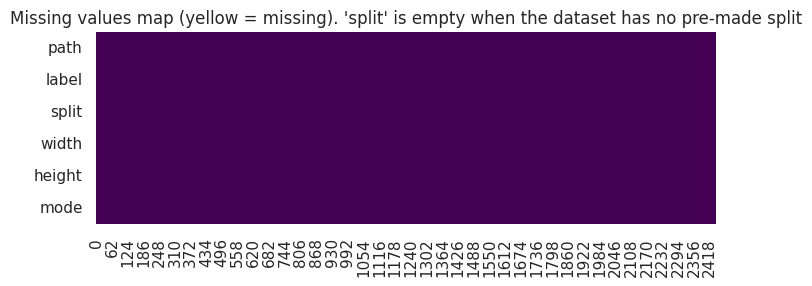

In [17]:
# Visualizing the missing values
plt.figure(figsize=(8, 2.5))
sns.heatmap(df[["path", "label", "split", "width", "height", "mode"]].isnull().T, cbar=False, cmap="viridis")
plt.title("Missing values map (yellow = missing). 'split' is empty when the dataset has no pre-made split")
plt.show()

### What did you know about your dataset?

The dataset is a folder of brain-MRI images where the **parent folder name is the label** (tumor category). The audit above tells us the number of images, the number of classes, whether a ready-made train/test split exists, whether any files are corrupt, and whether exact duplicate images exist (including duplicates that would leak between train and test). Image width, height and colour mode are collected for the next section. Exact counts are printed in the cells above, because they depend on the downloaded copy of the dataset.

## ***2. Understanding Your Variables***

In [18]:
# Dataset Columns
print(list(df.columns))

['path', 'label', 'split', 'md5', 'width', 'height', 'mode', 'corrupt']


In [19]:
# Dataset Describe (image resolution statistics)
df[["width", "height"]].describe()

,width,height
count,2443.0,2443.0
mean,640.0,640.0
std,0.0,0.0
min,640.0,640.0
25%,640.0,640.0
50%,640.0,640.0
75%,640.0,640.0
max,640.0,640.0


### Variables Description

| Column | Meaning |
|---|---|
| `path` | Full path of the MRI image file |
| `label` | Tumor category = **target variable** (taken from the class folder name) |
| `split` | train / val / test, taken from the folder structure when available |
| `md5` | Hash of the file content, used to detect exact duplicates |
| `width`, `height` | Original image resolution in pixels |
| `mode` | Colour mode of the file (e.g. `L` grayscale, `RGB`) |
| `corrupt` | True if the file could not be opened/verified |

### Check Unique Values for each variable.

In [20]:
# Check Unique Values for each variable.
for c in ["label", "split", "mode", "width", "height"]:
    print(f"{c:7s} -> {df[c].nunique():4d} unique | sample: {list(df[c].dropna().unique()[:8])}")

label   ->    4 unique | sample: ['no_tumor', 'meningioma', 'pituitary', 'glioma']
split   ->    3 unique | sample: ['test', 'train', 'val']
mode    ->    1 unique | sample: ['RGB']
width   ->    1 unique | sample: [np.int64(640)]
height  ->    1 unique | sample: [np.int64(640)]


## 3. ***Data Wrangling***

### Data Wrangling Code

In [21]:
# Make the dataset analysis-ready:
#   1) drop corrupt files, 2) drop exact duplicates (train copy is kept, so val/test never contain a train image),
#   3) make sure train / val / test splits exist, 4) encode labels as integers.
n_before = len(df)
priority = {"train": 0, "val": 1, "test": 2}
df["_prio"] = df["split"].map(priority).fillna(0)
df = (df[~df["corrupt"]]
        .sort_values("_prio", kind="stable")
        .drop_duplicates("md5", keep="first")
        .drop(columns="_prio")
        .reset_index(drop=True))
print(f"Removed {n_before - len(df)} corrupt/duplicate images  ({n_before} -> {len(df)})")

def ensure_splits(d):
    """Use the dataset's own split when present; otherwise create a stratified split."""
    d = d.copy()
    present = set(d["split"].dropna())
    if "train" not in present:                                   # no usable split -> 70 / 15 / 15
        d["split"] = None
        tr, tmp = train_test_split(d, test_size=0.30, stratify=d["label"], random_state=SEED)
        va, te = train_test_split(tmp, test_size=0.50, stratify=tmp["label"], random_state=SEED)
        d.loc[tr.index, "split"] = "train"
        d.loc[va.index, "split"] = "val"
        d.loc[te.index, "split"] = "test"
        return d
    d["split"] = d["split"].fillna("train")
    for missing in ["val", "test"]:                              # carve 15% of train for a missing split
        if missing not in set(d["split"]):
            tr = d[d["split"] == "train"]
            _, carve = train_test_split(tr, test_size=0.15, stratify=tr["label"], random_state=SEED)
            d.loc[carve.index, "split"] = missing
    return d

df = ensure_splits(df)

class_names = sorted(df["label"].unique())
label2idx = {c: i for i, c in enumerate(class_names)}
df["label_idx"] = df["label"].map(label2idx)
NUM_CLASSES = len(class_names)

train_df = df[df["split"] == "train"].reset_index(drop=True)
val_df   = df[df["split"] == "val"].reset_index(drop=True)
test_df  = df[df["split"] == "test"].reset_index(drop=True)

print("Classes:", label2idx)
print(f"Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}")

Removed 0 corrupt/duplicate images  (2443 -> 2443)
Classes: {'glioma': 0, 'meningioma': 1, 'no_tumor': 2, 'pituitary': 3}
Train: 1695 | Val: 502 | Test: 246


### What all manipulations have you done and insights you found?

1. **Corrupt files removed** so that training never crashes on a bad image.
2. **Exact duplicates removed** (the copy in the training set is kept). This matters in medical imaging: if the same scan sits in both train and test, the test accuracy is artificially high.
3. **Splits ensured**: the dataset's own train/val/test split is respected; any missing split is carved out with *stratified* sampling so every class keeps the same proportion.
4. **Labels encoded** to integers 0..N-1 (alphabetical class order), which is the order the models output probabilities in. The same order is saved to `class_names.json` for the Streamlit app.

## ***4. Data Vizualization, Storytelling & Experimenting with charts : Understand the relationships between variables***

#### Chart - 1 : Class Distribution (Univariate)

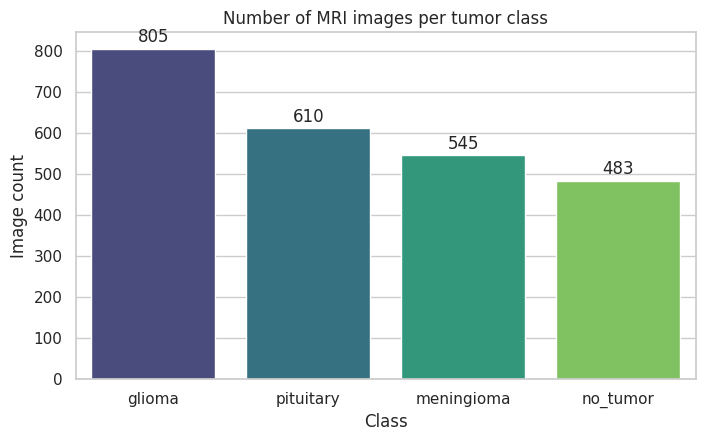

label
glioma        805
pituitary     610
meningioma    545
no_tumor      483

Largest / smallest class ratio = 1.67


In [22]:
# Chart - 1 visualization code
order = df["label"].value_counts().index
plt.figure(figsize=(8, 4.5))
ax = sns.countplot(data=df, x="label", order=order, palette="viridis")
for c in ax.containers:
    ax.bar_label(c, padding=2)
plt.title("Number of MRI images per tumor class")
plt.xlabel("Class"); plt.ylabel("Image count")
plt.show()

counts = df["label"].value_counts()
print(counts.to_string())
print(f"\nLargest / smallest class ratio = {counts.max() / counts.min():.2f}")

##### 1. Why did you pick the specific chart?

A count plot (bar chart) is the standard way to see the frequency of each category. For a classification problem it is the first thing to check, because the class balance decides which metric and which training strategy we should use.

##### 2. What is/are the insight(s) found from the chart?

The bar heights and the printed ratio show how balanced the classes are. If the largest/smallest ratio is close to 1 the data is balanced; a large ratio means the model can become biased towards the majority class and plain accuracy becomes misleading.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** it tells us up-front to report precision/recall/F1 per class and to use class weights, so the model does not ignore rare tumor types. **Negative risk:** if a tumor class is much smaller than the rest, a model trained without correction would miss exactly those patients - in a hospital this means false negatives, which is the costliest kind of error. This is why class weights are used in Section 5.

#### Chart - 2 : Class Distribution per Split (Bivariate: Categorical vs Categorical)

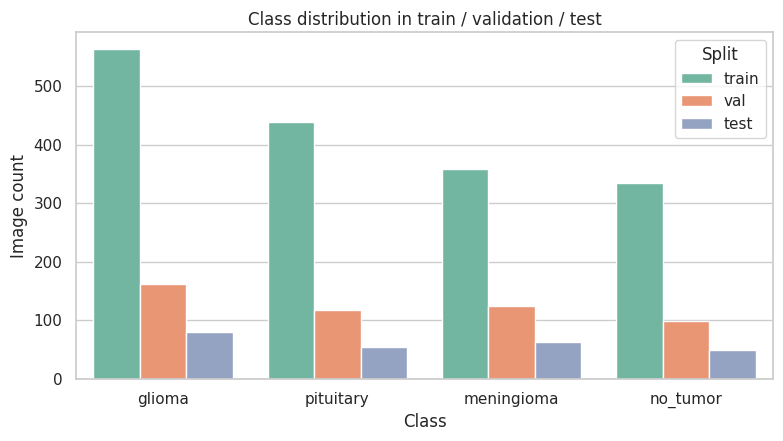

Class share (%) inside each split:
label  glioma  meningioma  no_tumor  pituitary
split                                         
test     32.5        25.6      19.9       22.0
train    33.3        21.1      19.8       25.8
val      32.1        24.7      19.7       23.5


In [23]:
# Chart - 2 visualization code
split_order = [s for s in ["train", "val", "test"] if s in df["split"].unique()]
plt.figure(figsize=(9, 4.5))
sns.countplot(data=df, x="label", hue="split", hue_order=split_order, order=order, palette="Set2")
plt.title("Class distribution in train / validation / test")
plt.xlabel("Class"); plt.ylabel("Image count")
plt.legend(title="Split")
plt.show()

prop = pd.crosstab(df["split"], df["label"], normalize="index").round(3) * 100
print("Class share (%) inside each split:")
print(prop.to_string())

##### 1. Why did you pick the specific chart?

A grouped bar chart compares two categorical variables (class and split) in one view, so we can check that the three splits contain the classes in similar proportions.

##### 2. What is/are the insight(s) found from the chart?

The percentage table shows whether train, validation and test have a similar class mix. Similar proportions mean the validation/test scores are a fair estimate of real-world performance; very different proportions would make the scores unreliable.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** a representative test set gives trustworthy numbers that can be shown to clinicians and stakeholders. **Negative risk:** if a class is almost absent in the test set, its recall is statistically meaningless and a weak model could look good. If that happens the split should be re-balanced before deployment.

#### Chart - 3 : Sample MRI Images per Class

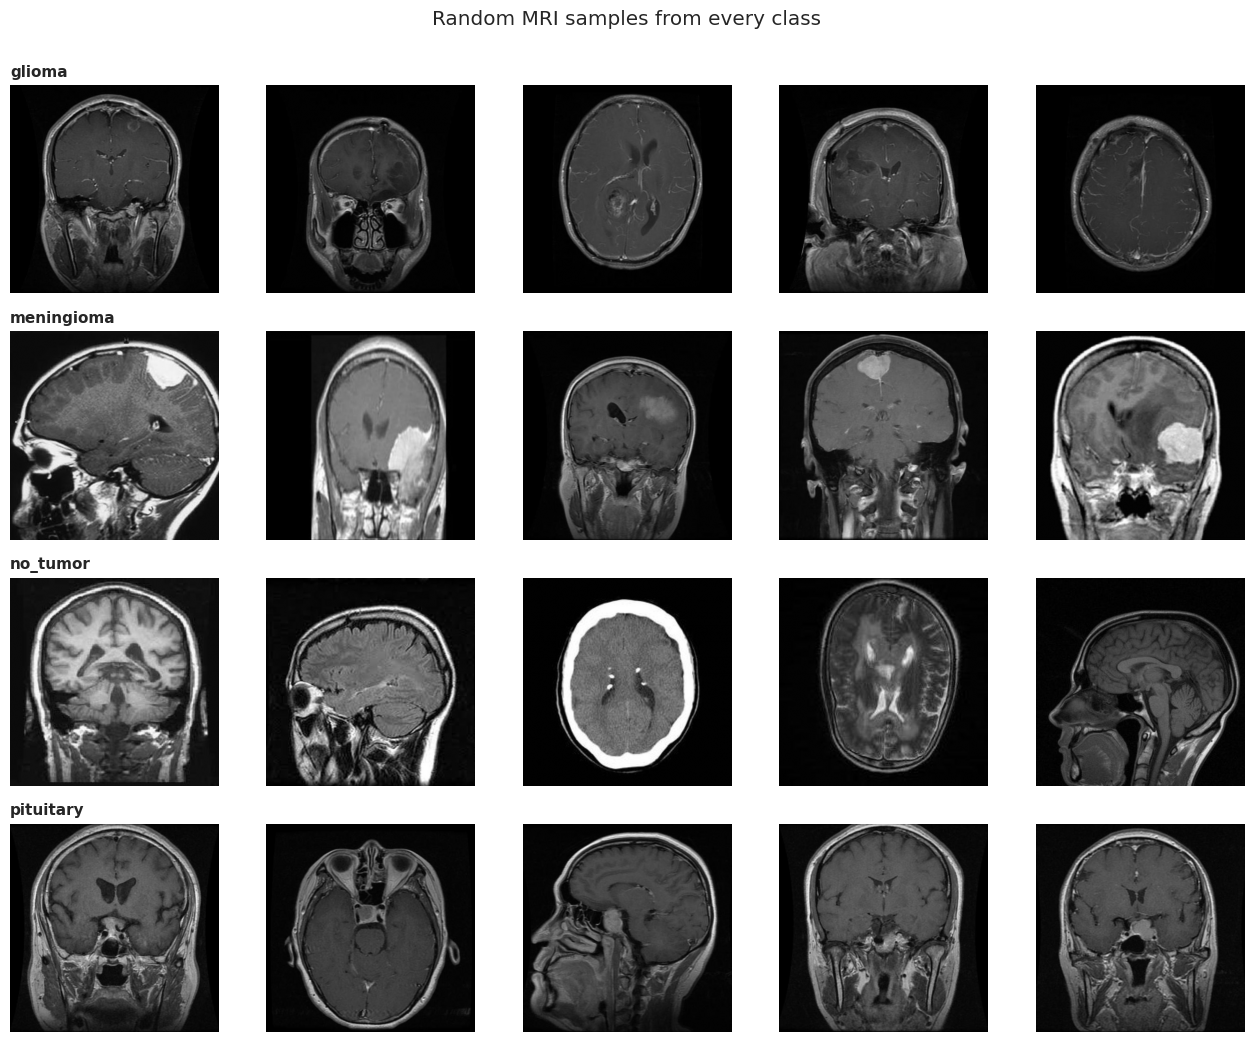

In [24]:
# Chart - 3 visualization code
n_show = 5
fig, axes = plt.subplots(NUM_CLASSES, n_show, figsize=(2.6 * n_show, 2.6 * NUM_CLASSES))
axes = np.atleast_2d(axes)
for r, cls in enumerate(class_names):
    paths = df[df["label"] == cls]["path"].sample(n_show, random_state=SEED, replace=len(df[df["label"] == cls]) < n_show)
    for c, p in enumerate(paths):
        axes[r, c].imshow(Image.open(p).convert("L"), cmap="gray")
        axes[r, c].axis("off")
        if c == 0:
            axes[r, c].set_title(cls, loc="left", fontsize=11, fontweight="bold")
plt.suptitle("Random MRI samples from every class", y=1.0)
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

For image data, looking at real examples is the most important 'chart'. It shows scan orientation, contrast, zoom level, black borders and the visual difficulty of telling the classes apart.

##### 2. What is/are the insight(s) found from the chart?

The samples show that MRI slices differ in orientation (axial / sagittal / coronal), brightness, zoom and position of the head. Some classes can look very similar to the naked eye, which is why a deep model that learns texture and shape is needed rather than simple rules. The variation in orientation and brightness also justifies the augmentation used later.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** it confirms the images are usable and that augmentation (rotation, flip, zoom, brightness) will reflect real variation between scanners and patients. **Negative risk:** differences in acquisition (contrast, borders) can let a model 'cheat' by learning scanner artefacts instead of the tumor; this is a known risk in medical imaging and one reason the tool should only assist, not replace, a radiologist.

#### Chart - 4 : Image Resolution Distribution (Bivariate: Numerical vs Numerical)

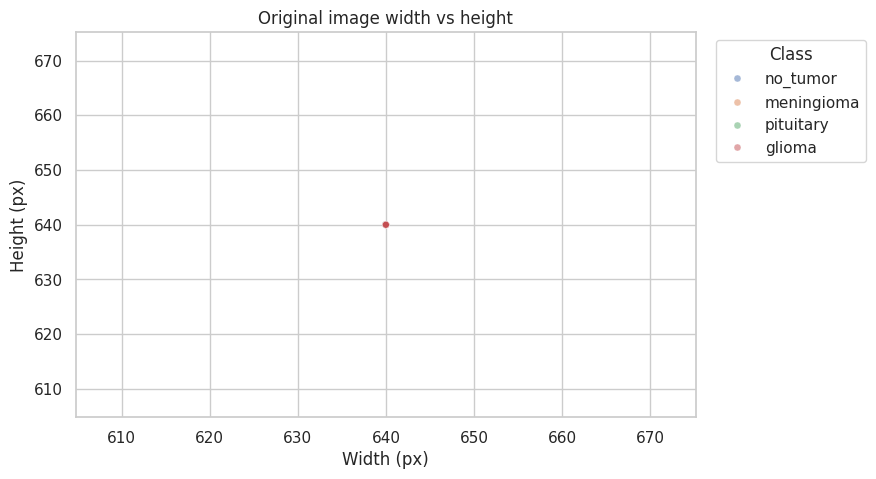

Distinct resolutions: 1
width  height
640    640       2443
Colour modes: {'RGB': 2443}


In [25]:
# Chart - 4 visualization code
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="width", y="height", hue="label", alpha=0.5, s=25)
plt.title("Original image width vs height")
plt.xlabel("Width (px)"); plt.ylabel("Height (px)")
plt.legend(title="Class", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()

print("Distinct resolutions:", df.groupby(["width", "height"]).ngroups)
print(df.groupby(["width", "height"]).size().sort_values(ascending=False).head(5).to_string())
print("Colour modes:", df["mode"].value_counts().to_dict())

##### 1. Why did you pick the specific chart?

A scatter plot of width vs height shows at a glance whether all images have the same size. Each dot is an image, so clusters reveal the common resolutions.

##### 2. What is/are the insight(s) found from the chart?

The scatter plot and the table show how many different resolutions exist. If the sizes vary, a resize step is mandatory because neural networks need a fixed input shape. The colour-mode counts show if some files are grayscale and some RGB, which is why every image is converted to 3 channels in the pipeline.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** it justifies the standard preprocessing (resize to 224x224, 3 channels) and avoids shape errors in production. **Negative risk:** resizing very non-square images stretches them and can distort the tumor shape slightly; if the aspect ratios were very different, padding instead of stretching would be a better choice.

#### Chart - 5 : Pixel Intensity per Class (Bivariate: Numerical vs Categorical)

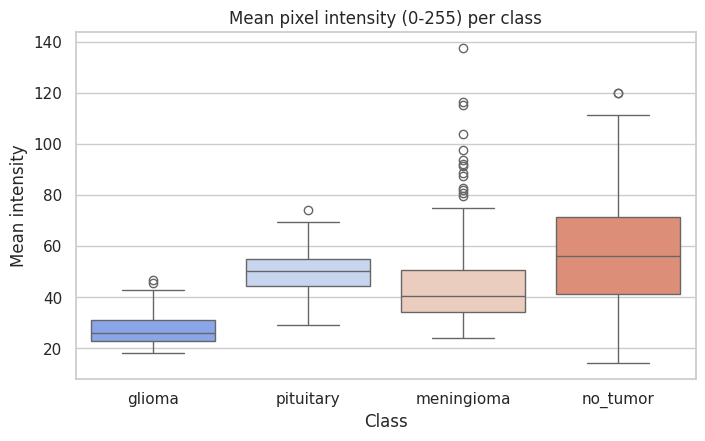

                 mean        std
label                           
glioma      27.400000   5.700000
meningioma  46.799999  19.799999
no_tumor    59.000000  21.600000
pituitary   49.500000   8.600000


In [26]:
# Chart - 5 visualization code
# Mean brightness of up to 150 random images per class (images shrunk to 64x64 for speed)
recs = []
for cls in class_names:
    sub = df[df["label"] == cls]
    for p in sub["path"].sample(min(150, len(sub)), random_state=SEED):
        arr = np.asarray(Image.open(p).convert("L").resize((64, 64)), dtype=np.float32)
        recs.append((cls, arr.mean()))
inten = pd.DataFrame(recs, columns=["label", "mean_intensity"])

plt.figure(figsize=(8, 4.5))
sns.boxplot(data=inten, x="label", y="mean_intensity", order=order, palette="coolwarm")
plt.title("Mean pixel intensity (0-255) per class")
plt.xlabel("Class"); plt.ylabel("Mean intensity")
plt.show()

print(inten.groupby("label")["mean_intensity"].agg(["mean", "std"]).round(1).to_string())

##### 1. Why did you pick the specific chart?

A box plot compares a numeric variable (brightness) across categories and also shows the spread and outliers, which a bar chart of averages would hide.

##### 2. What is/are the insight(s) found from the chart?

If the average brightness differs clearly between classes, brightness alone carries some class information - which can be real (tissue appearance) or an artefact (different scanner settings per class). Wide boxes and outliers show how much the scans vary in exposure, which supports using normalisation and brightness augmentation.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** it supports normalising pixel values to 0-1 and adding brightness augmentation so the model depends on structure, not on exposure. **Negative risk:** if one class is much brighter than the others, the model may learn 'bright = tumor type X', which would fail on scans from a different hospital. Evaluating on a separate-hospital dataset before real deployment would be needed.

#### Chart - 6 : Effect of Data Augmentation (Multivariate view of transformations)

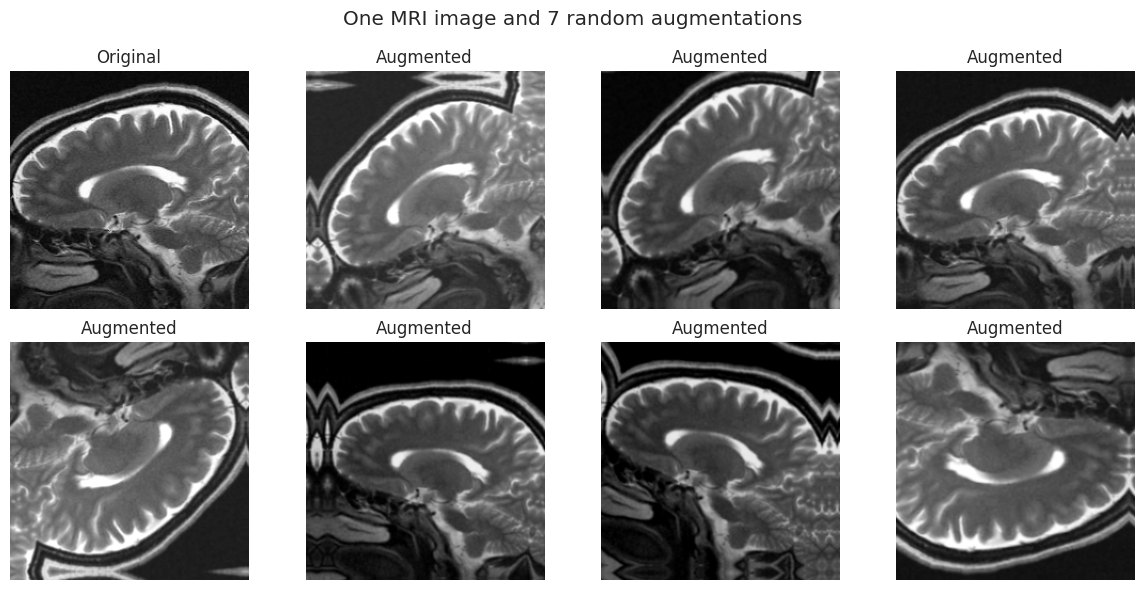

In [27]:
# Chart - 6 visualization code
# Augmentation block used for training (defined here so it can be visualised, reused in Section 5)
augment = keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.08),                       # about +/- 29 degrees
    layers.RandomZoom(0.10),
    layers.RandomTranslation(0.05, 0.05),
    layers.RandomBrightness(0.10, value_range=(0, 255)),
], name="augmentation")

sample_path = train_df["path"].iloc[0]
img = tf.image.resize(tf.io.decode_image(tf.io.read_file(sample_path), channels=3, expand_animations=False), IMG_SIZE)
img = tf.expand_dims(tf.cast(img, tf.float32), 0)

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
axes[0, 0].imshow(img[0].numpy().astype("uint8")); axes[0, 0].set_title("Original")
for ax in axes.flat[1:]:
    ax.imshow(np.clip(augment(img, training=True)[0].numpy(), 0, 255).astype("uint8"))
    ax.set_title("Augmented")
for ax in axes.flat:
    ax.axis("off")
plt.suptitle("One MRI image and 7 random augmentations")
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A side-by-side image grid is the clearest way to verify that the augmentations are realistic: we must see that the tumor stays visible and the image still looks like a plausible MRI.

##### 2. What is/are the insight(s) found from the chart?

The augmented copies show flips, rotations, zoom, shifts and brightness changes applied randomly. The anatomy remains recognisable, so these transformations create new, realistic training examples instead of destroying information.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** augmentation effectively multiplies the training data, reduces overfitting, and makes the model robust to patient positioning and scanner differences - fewer wrong predictions in real use. **Negative risk:** too strong augmentation (e.g. very large rotations) could create unrealistic images and hurt accuracy, so the parameters are kept moderate. Vertical flip is anatomically unusual for brain scans; it is included because the project brief lists it, and it can be switched off in the `augment` block if validation accuracy drops.

> **Note on the template's "15 charts" rule:** 15 charts are suited to tabular data. For an image dataset, the 6 charts above cover every meaningful view (class balance, split balance, visual samples, resolution, intensity, augmentation). Section 7 adds model-performance charts (training curves, confusion matrices, model comparison, confidence histogram), which brings the total to more than 15 visualisations in this notebook.

## ***5. Data Pre-processing & Input Pipeline***

### 1. Resizing & Normalisation

Every image is decoded as 3-channel, resized to **224x224** and kept as float 0-255 inside the `tf.data` pipeline. The **normalisation is the first layer inside each model** (custom CNN: `Rescaling(1/255)` -> 0-1 range; MobileNetV2 / InceptionV3: scaled to -1..1; EfficientNetB0: has its own built-in normalisation). Doing it inside the model has a big practical advantage: the saved `.h5` file accepts a raw image, so the Streamlit app needs **no separate preprocessing code** and train/inference can never get out of sync.

In [28]:
# tf.data input pipeline
AUTOTUNE = tf.data.AUTOTUNE

def load_image(path, label):
    img = tf.io.read_file(path)
    img = tf.io.decode_image(img, channels=3, expand_animations=False)   # grayscale / RGBA -> 3 channels
    img = tf.image.resize(img, IMG_SIZE)                                  # float32, range 0-255
    img.set_shape((*IMG_SIZE, 3))
    return img, label

def make_ds(d, training):
    ds = tf.data.Dataset.from_tensor_slices((d["path"].values, d["label_idx"].values.astype("int32")))
    if training:
        ds = ds.shuffle(len(d), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE).batch(BATCH_SIZE)
    if training:                                                          # augmentation ONLY for training data
        ds = ds.map(lambda x, y: (augment(x, training=True), y), num_parallel_calls=AUTOTUNE)
    return ds.prefetch(AUTOTUNE)

train_ds = make_ds(train_df, training=True)
val_ds   = make_ds(val_df,   training=False)
test_ds  = make_ds(test_df,  training=False)   # not shuffled -> prediction order == test_df order
print("Pipelines ready.")

Pipelines ready.


### 2. Data Augmentation

Already defined in Chart 6 (`augment`): horizontal/vertical flip, rotation, zoom, shift and brightness. It is applied **only to the training pipeline**; validation and test images are never augmented, so their scores stay honest.

### 3. Handling Imbalanced Dataset

##### Do you think the dataset is imbalanced? Explain Why.

Check the class-ratio printed under Chart 1. Even a moderate imbalance (for example one class having 30-40% fewer images) is enough to make a model slightly favour the larger classes. For a medical task, that is unacceptable, so imbalance is handled regardless of how large it is.

In [29]:
# Handling Imbalanced Dataset: balanced class weights (rare classes get a larger weight in the loss)
cw = compute_class_weight("balanced", classes=np.arange(NUM_CLASSES), y=train_df["label_idx"].values)
class_weights = {i: float(w) for i, w in enumerate(cw)}
print({class_names[i]: round(w, 3) for i, w in class_weights.items()})

{'glioma': 0.751, 'meningioma': 1.184, 'no_tumor': 1.265, 'pituitary': 0.967}


##### What technique did you use to handle the imbalance dataset and why?

**Class weights** (`compute_class_weight('balanced')`). Compared with over/under-sampling, weights need no extra images, keep every real scan, and simply make a mistake on a rare class cost more during training. Augmentation also helps the smaller classes.

## ***6. ML (Deep Learning) Model Implementation***

### Model-building helpers

In [30]:
# ---------- Model 1: Custom CNN built from scratch ----------
def build_custom_cnn(num_classes=NUM_CLASSES):
    inp = keras.Input(shape=(*IMG_SIZE, 3), name="image")
    x = layers.Rescaling(1.0 / 255, name="normalize_0_1")(inp)             # pixel values -> 0-1
    for filters in [32, 64, 128, 256]:                                     # 4 convolution blocks
        x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
        x = layers.BatchNormalization()(x)                                 # stabilises & speeds up learning
        x = layers.Activation("relu")(x)
        x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation("relu")(x)
        x = layers.MaxPooling2D()(x)                                       # halve the spatial size
        x = layers.Dropout(0.25)(x)                                        # regularisation
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.5)(x)
    out = layers.Dense(num_classes, activation="softmax", name="probs")(x)
    return keras.Model(inp, out, name="CustomCNN")

# ---------- Models 2-4: Transfer learning (ImageNet backbones) ----------
BACKBONES = {
    "MobileNetV2":    (keras.applications.MobileNetV2,    "minus1_1"),   # expects -1..1
    "EfficientNetB0": (keras.applications.EfficientNetB0, "builtin"),    # has its own Rescaling (expects 0-255)
    "InceptionV3":    (keras.applications.InceptionV3,    "minus1_1"),   # expects -1..1
}

def build_transfer_model(name, num_classes=NUM_CLASSES):
    base_fn, norm = BACKBONES[name]
    base = base_fn(include_top=False, weights=WEIGHTS, input_shape=(*IMG_SIZE, 3))
    base.trainable = False                                                 # phase 1: backbone frozen
    inp = keras.Input(shape=(*IMG_SIZE, 3), name="image")
    x = layers.Rescaling(1.0 / 127.5, offset=-1, name="normalize")(inp) if norm == "minus1_1" else inp
    x = base(x, training=False)                                            # keep BatchNorm in inference mode
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(256, activation="relu")(x)                            # new classification head
    x = layers.Dropout(0.4)(x)
    out = layers.Dense(num_classes, activation="softmax", name="probs")(x)
    return keras.Model(inp, out, name=name), base

In [31]:
# ---------- Training routine (callbacks, class weights, two-phase fine-tuning) ----------
results = {}   # name -> dict(history, train_time)

def train_model(name):
    tf.keras.backend.clear_session()
    ckpt = os.path.join(MODEL_DIR, f"{name}.h5")
    t0 = time.time()

    if name == "CustomCNN":
        model, base = build_custom_cnn(), None
    else:
        model, base = build_transfer_model(name)

    # ----- Phase 1: train the new head (or the whole CNN) -----
    model.compile(optimizer=keras.optimizers.Adam(1e-3),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    cbs = [
        EarlyStopping(monitor="val_loss", patience=6 if base is None else 4, restore_best_weights=True),
        ModelCheckpoint(ckpt, monitor="val_loss", save_best_only=True),           # saves best model as .h5
        ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=2, min_lr=1e-7),
    ]
    h1 = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS,
                   class_weight=class_weights, callbacks=cbs, verbose=1)
    hist = {k: list(v) for k, v in h1.history.items()}
    best_val = min(hist["val_loss"])
    phase1_epochs = len(hist["val_loss"])

    # ----- Phase 2 (transfer models only): fine-tune the top backbone layers with a tiny learning rate -----
    if base is not None and FINE_TUNE_EPOCHS > 0:
        base.trainable = True
        for layer in base.layers[:-FINE_TUNE_AT]:
            layer.trainable = False
        for layer in base.layers:                                            # keep BatchNorm statistics frozen
            if isinstance(layer, layers.BatchNormalization):
                layer.trainable = False
        model.compile(optimizer=keras.optimizers.Adam(1e-5),
                      loss="sparse_categorical_crossentropy", metrics=["accuracy"])
        cbs2 = [
            EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True),
            # only overwrite the .h5 file if fine-tuning beats phase 1
            ModelCheckpoint(ckpt, monitor="val_loss", save_best_only=True, initial_value_threshold=best_val),
            ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=1, min_lr=1e-8),
        ]
        h2 = model.fit(train_ds, validation_data=val_ds, epochs=FINE_TUNE_EPOCHS,
                       class_weight=class_weights, callbacks=cbs2, verbose=1)
        for k, v in h2.history.items():
            hist.setdefault(k, []).extend(v)

    results[name] = {"history": hist, "phase1_epochs": phase1_epochs,
                     "train_time_min": (time.time() - t0) / 60}
    print(f"\n{name}: finished in {results[name]['train_time_min']:.1f} min | best val_loss = {min(hist['val_loss']):.4f}")
    return model

### ML Model - 1 : Custom CNN (from scratch)

In [32]:
# ML Model - 1 Implementation (Custom CNN)
cnn_model = train_model("CustomCNN")
cnn_model.summary()

Epoch 1/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.5299 - loss: 1.3689   

53/53 ━━━━━━━━━━━━━━━━━━━━ 103s 1s/step - accuracy: 0.5794 - loss: 1.2204 - val_accuracy: 0.3207 - val_loss: 2.4831 - learning_rate: 0.0010
Epoch 2/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 74s 541ms/step - accuracy: 0.6360 - loss: 1.0140 - val_accuracy: 0.3207 - val_loss: 3.0570 - learning_rate: 0.0010
Epoch 3/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 30s 556ms/step - accuracy: 0.6460 - loss: 0.9388 - val_accuracy: 0.3207 - val_loss: 3.6535 - learning_rate: 0.0010
Epoch 4/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 29s 530ms/step - accuracy: 0.6920 - loss: 0.8449 - val_accuracy: 0.3207 - val_loss: 4.3139 - learning_rate: 3.0000e-04
Epoch 5/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 41s 534ms/step - accuracy: 0.7198 - loss: 0.7691 - val_accuracy: 0.3207 - val_loss: 4.5691 - learning_rate: 3.0000e-04
Epoch 6/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 28s 521ms/step - accuracy: 0.7469 - loss: 0.7189 - val_accuracy: 0.3207 - val_loss: 4.6348 - learning_rate: 9.0000e-05
Epoch 7/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 28s 519ms/step - accuracy: 0.7599 - loss: 0.7

Model: "CustomCNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ normalize_0_1 (Rescaling)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 224, 224, 32)   │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 112, 112, 64)   │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 112, 112, 64)   │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 56, 56, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 56, 56, 128)    │       147,456 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 3,724,078 (14.21 MB)

 Trainable params: 1,240,548 (4.73 MB)

 Non-trainable params: 2,432 (9.50 KB)

 Optimizer params: 2,481,098 (9.46 MB)

#### 1. Explain the ML Model used and its performance
A **Convolutional Neural Network** learns image features automatically: early layers detect edges and textures, deeper layers detect shapes and tumor-specific patterns. This custom network has 4 blocks of two 3x3 convolutions, **BatchNormalization** (stabilises learning), **MaxPooling** (reduces size), and **Dropout** (prevents overfitting), followed by global average pooling and a dense softmax layer that outputs one probability per tumor class. It is trained from random weights, so it is the *baseline* to see how much transfer learning adds. Its performance (accuracy, precision, recall, F1) is reported in Section 7.

#### 2. Cross-validation & hyper-parameter tuning
Instead of GridSearchCV (too expensive for deep nets), tuning is done with **callbacks**: `ReduceLROnPlateau` automatically lowers the learning rate when validation loss stalls, `EarlyStopping` stops training before overfitting, and `ModelCheckpoint` keeps the best weights. A held-out validation set takes the role of cross-validation.

### ML Model - 2 : MobileNetV2 (Transfer Learning)

In [33]:
# ML Model - 2 Implementation (MobileNetV2)
mnet_model = train_model("MobileNetV2")

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 525ms/step - accuracy: 0.5062 - loss: 1.3449

53/53 ━━━━━━━━━━━━━━━━━━━━ 53s 711ms/step - accuracy: 0.6448 - loss: 0.9497 - val_accuracy: 0.7709 - val_loss: 0.5939 - learning_rate: 0.0010
Epoch 2/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 461ms/step - accuracy: 0.8004 - loss: 0.5629

53/53 ━━━━━━━━━━━━━━━━━━━━ 28s 495ms/step - accuracy: 0.8088 - loss: 0.5383 - val_accuracy: 0.7829 - val_loss: 0.5610 - learning_rate: 0.0010
Epoch 3/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 40s 479ms/step - accuracy: 0.8077 - loss: 0.5109 - val_accuracy: 0.7729 - val_loss: 0.6139 - learning_rate: 0.0010
Epoch 4/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 474ms/step - accuracy: 0.8323 - loss: 0.4501

53/53 ━━━━━━━━━━━━━━━━━━━━ 42s 500ms/step - accuracy: 0.8271 - loss: 0.4641 - val_accuracy: 0.8287 - val_loss: 0.4923 - learning_rate: 0.0010
Epoch 5/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 41s 515ms/step - accuracy: 0.8537 - loss: 0.4152 - val_accuracy: 0.7191 - val_loss: 0.8219 - learning_rate: 0.0010
Epoch 6/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 498ms/step - accuracy: 0.8389 - loss: 0.4322

53/53 ━━━━━━━━━━━━━━━━━━━━ 42s 532ms/step - accuracy: 0.8460 - loss: 0.4149 - val_accuracy: 0.8367 - val_loss: 0.4375 - learning_rate: 0.0010
Epoch 7/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 489ms/step - accuracy: 0.8538 - loss: 0.4054

53/53 ━━━━━━━━━━━━━━━━━━━━ 28s 523ms/step - accuracy: 0.8596 - loss: 0.3922 - val_accuracy: 0.8566 - val_loss: 0.4372 - learning_rate: 0.0010
Epoch 8/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 40s 509ms/step - accuracy: 0.8578 - loss: 0.3888 - val_accuracy: 0.8207 - val_loss: 0.5342 - learning_rate: 0.0010
Epoch 9/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 461ms/step - accuracy: 0.8681 - loss: 0.3678

53/53 ━━━━━━━━━━━━━━━━━━━━ 28s 520ms/step - accuracy: 0.8755 - loss: 0.3498 - val_accuracy: 0.8606 - val_loss: 0.4214 - learning_rate: 0.0010
Epoch 10/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 27s 507ms/step - accuracy: 0.8737 - loss: 0.3510 - val_accuracy: 0.8367 - val_loss: 0.4791 - learning_rate: 0.0010
Epoch 11/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 448ms/step - accuracy: 0.8891 - loss: 0.3063

53/53 ━━━━━━━━━━━━━━━━━━━━ 26s 484ms/step - accuracy: 0.8826 - loss: 0.3206 - val_accuracy: 0.8765 - val_loss: 0.4028 - learning_rate: 0.0010
Epoch 12/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 40s 469ms/step - accuracy: 0.8820 - loss: 0.3374 - val_accuracy: 0.8347 - val_loss: 0.4549 - learning_rate: 0.0010
Epoch 13/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 27s 492ms/step - accuracy: 0.8791 - loss: 0.3331 - val_accuracy: 0.8347 - val_loss: 0.4585 - learning_rate: 0.0010
Epoch 14/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 41s 508ms/step - accuracy: 0.8814 - loss: 0.3199 - val_accuracy: 0.8287 - val_loss: 0.4434 - learning_rate: 3.0000e-04
Epoch 15/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 28s 511ms/step - accuracy: 0.9038 - loss: 0.2690 - val_accuracy: 0.8466 - val_loss: 0.4350 - learning_rate: 3.0000e-04
Epoch 1/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 56s 731ms/step - accuracy: 0.8761 - loss: 0.3336 - val_accuracy: 0.8028 - val_loss: 0.5737 - learning_rate: 1.0000e-05
Epoch 2/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 27s 492ms/step - accuracy: 0.8932 - los

53/53 ━━━━━━━━━━━━━━━━━━━━ 29s 537ms/step - accuracy: 0.9174 - loss: 0.2313 - val_accuracy: 0.8825 - val_loss: 0.3668 - learning_rate: 3.0000e-06
Epoch 7/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 40s 515ms/step - accuracy: 0.9245 - loss: 0.2262 - val_accuracy: 0.8625 - val_loss: 0.4248 - learning_rate: 3.0000e-06
Epoch 8/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 41s 506ms/step - accuracy: 0.9139 - loss: 0.2384 - val_accuracy: 0.8546 - val_loss: 0.4279 - learning_rate: 9.0000e-07
Epoch 9/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 40s 491ms/step - accuracy: 0.9233 - loss: 0.2358 - val_accuracy: 0.8645 - val_loss: 0.4149 - learning_rate: 2.7000e-07

MobileNetV2: finished in 14.6 min | best val_loss = 0.3668


#### 1. Explain the ML Model used and its performance
**MobileNetV2** is a light, fast network pretrained on ImageNet (1000 classes) using depthwise-separable convolutions and inverted residual blocks. Its already-learned edge/texture detectors transfer well to MRI images. We remove its ImageNet classifier, add a new head (GAP -> Dropout -> Dense(256) -> Dropout -> softmax), train the head first, then **fine-tune the top 40 layers**. Because it is small, it is the best candidate when speed or low memory matters (e.g. a hospital PC without a GPU). Results are in Section 7.

#### 2. Hyper-parameter tuning
Two-phase training: learning rate 1e-3 for the new head, then 1e-5 for fine-tuning (a tiny rate so the pretrained weights are only gently adjusted). BatchNorm layers stay frozen during fine-tuning, which is the recommended practice for stability. The fine-tuned weights are saved only if they beat the phase-1 validation loss.

### ML Model - 3 : EfficientNetB0 (Transfer Learning)

In [34]:
# ML Model - 3 Implementation (EfficientNetB0)
eff_model = train_model("EfficientNetB0")

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 678ms/step - accuracy: 0.5721 - loss: 1.0218

53/53 ━━━━━━━━━━━━━━━━━━━━ 90s 1s/step - accuracy: 0.6814 - loss: 0.8085 - val_accuracy: 0.6335 - val_loss: 0.8956 - learning_rate: 0.0010
Epoch 2/20
52/53 ━━━━━━━━━━━━━━━━━━━━ 0s 482ms/step - accuracy: 0.7844 - loss: 0.6063

53/53 ━━━━━━━━━━━━━━━━━━━━ 27s 502ms/step - accuracy: 0.7953 - loss: 0.5598 - val_accuracy: 0.7849 - val_loss: 0.5873 - learning_rate: 0.0010
Epoch 3/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 470ms/step - accuracy: 0.8311 - loss: 0.4635

53/53 ━━━━━━━━━━━━━━━━━━━━ 27s 497ms/step - accuracy: 0.8230 - loss: 0.4759 - val_accuracy: 0.7689 - val_loss: 0.5627 - learning_rate: 0.0010
Epoch 4/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 41s 498ms/step - accuracy: 0.8336 - loss: 0.4508 - val_accuracy: 0.6932 - val_loss: 0.7171 - learning_rate: 0.0010
Epoch 5/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 41s 508ms/step - accuracy: 0.8525 - loss: 0.3946 - val_accuracy: 0.7649 - val_loss: 0.5799 - learning_rate: 0.0010
Epoch 6/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 40s 497ms/step - accuracy: 0.8560 - loss: 0.3870 - val_accuracy: 0.7490 - val_loss: 0.6220 - learning_rate: 3.0000e-04
Epoch 7/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 41s 497ms/step - accuracy: 0.8702 - loss: 0.3613 - val_accuracy: 0.7689 - val_loss: 0.5702 - learning_rate: 3.0000e-04
Epoch 1/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 85s 992ms/step - accuracy: 0.8395 - loss: 0.4105 - val_accuracy: 0.7251 - val_loss: 0.6925 - learning_rate: 1.0000e-05
Epoch 2/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 26s 487ms/step - accuracy: 0.8614 - loss: 0

#### 1. Explain the ML Model used and its performance
**EfficientNetB0** scales network depth, width and resolution together (compound scaling) and typically reaches higher accuracy than older networks of a similar size. It also contains its own input normalisation, so the raw 0-255 image is passed directly. Same head and two-phase training as MobileNetV2. Results are in Section 7.

#### 2. Hyper-parameter tuning
Same strategy as Model 2 (head training at 1e-3, fine-tuning the top 40 layers at 1e-5, callbacks for early stopping, LR reduction and checkpointing).

### ML Model - 4 : InceptionV3 (Transfer Learning)

In [35]:
# ML Model - 4 Implementation (InceptionV3)
inc_model = train_model("InceptionV3")

87910968/87910968 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 623ms/step - accuracy: 0.4695 - loss: 1.4553

53/53 ━━━━━━━━━━━━━━━━━━━━ 73s 964ms/step - accuracy: 0.5829 - loss: 1.0964 - val_accuracy: 0.6574 - val_loss: 0.8457 - learning_rate: 0.0010
Epoch 2/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 463ms/step - accuracy: 0.7160 - loss: 0.7776

53/53 ━━━━━━━━━━━━━━━━━━━━ 28s 507ms/step - accuracy: 0.7257 - loss: 0.7355 - val_accuracy: 0.7530 - val_loss: 0.6183 - learning_rate: 0.0010
Epoch 3/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 471ms/step - accuracy: 0.7571 - loss: 0.6416

53/53 ━━━━━━━━━━━━━━━━━━━━ 28s 513ms/step - accuracy: 0.7617 - loss: 0.6324 - val_accuracy: 0.8167 - val_loss: 0.5506 - learning_rate: 0.0010
Epoch 4/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 486ms/step - accuracy: 0.7868 - loss: 0.5817

53/53 ━━━━━━━━━━━━━━━━━━━━ 29s 526ms/step - accuracy: 0.7823 - loss: 0.5812 - val_accuracy: 0.8247 - val_loss: 0.5190 - learning_rate: 0.0010
Epoch 5/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 28s 526ms/step - accuracy: 0.7823 - loss: 0.5830 - val_accuracy: 0.7888 - val_loss: 0.5508 - learning_rate: 0.0010
Epoch 6/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 41s 519ms/step - accuracy: 0.7994 - loss: 0.5285 - val_accuracy: 0.7948 - val_loss: 0.5753 - learning_rate: 0.0010
Epoch 7/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 28s 520ms/step - accuracy: 0.8248 - loss: 0.4840 - val_accuracy: 0.8008 - val_loss: 0.5353 - learning_rate: 3.0000e-04
Epoch 8/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 465ms/step - accuracy: 0.8150 - loss: 0.4854

...

53/53 ━━━━━━━━━━━━━━━━━━━━ 27s 503ms/step - accuracy: 0.8324 - loss: 0.4472 - val_accuracy: 0.8367 - val_loss: 0.4864 - learning_rate: 3.0000e-04
Epoch 10/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 26s 477ms/step - accuracy: 0.8442 - loss: 0.4335 - val_accuracy: 0.8267 - val_loss: 0.5053 - learning_rate: 3.0000e-04
Epoch 11/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 41s 476ms/step - accuracy: 0.8307 - loss: 0.4735 - val_accuracy: 0.8247 - val_loss: 0.4975 - learning_rate: 3.0000e-04
Epoch 12/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 449ms/step - accuracy: 0.8402 - loss: 0.4417

53/53 ━━━━━━━━━━━━━━━━━━━━ 43s 519ms/step - accuracy: 0.8354 - loss: 0.4399 - val_accuracy: 0.8367 - val_loss: 0.4736 - learning_rate: 9.0000e-05
Epoch 13/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 39s 488ms/step - accuracy: 0.8496 - loss: 0.4206 - val_accuracy: 0.8207 - val_loss: 0.4819 - learning_rate: 9.0000e-05
Epoch 14/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 41s 488ms/step - accuracy: 0.8490 - loss: 0.4026 - val_accuracy: 0.8327 - val_loss: 0.4806 - learning_rate: 9.0000e-05
Epoch 15/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 27s 478ms/step - accuracy: 0.8478 - loss: 0.4179 - val_accuracy: 0.8207 - val_loss: 0.4904 - learning_rate: 2.7000e-05
Epoch 16/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 28s 509ms/step - accuracy: 0.8584 - loss: 0.3855 - val_accuracy: 0.8287 - val_loss: 0.4882 - learning_rate: 2.7000e-05
Epoch 1/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 69s 881ms/step - accuracy: 0.8431 - loss: 0.4447 - val_accuracy: 0.8207 - val_loss: 0.4952 - learning_rate: 1.0000e-05
Epoch 2/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 490ms/step - accuracy: 0

53/53 ━━━━━━━━━━━━━━━━━━━━ 50s 531ms/step - accuracy: 0.8596 - loss: 0.3959 - val_accuracy: 0.8327 - val_loss: 0.4728 - learning_rate: 1.0000e-05
Epoch 3/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 28s 510ms/step - accuracy: 0.8643 - loss: 0.3755 - val_accuracy: 0.8267 - val_loss: 0.4785 - learning_rate: 1.0000e-05
Epoch 4/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 448ms/step - accuracy: 0.8799 - loss: 0.3639

53/53 ━━━━━━━━━━━━━━━━━━━━ 27s 498ms/step - accuracy: 0.8808 - loss: 0.3530 - val_accuracy: 0.8506 - val_loss: 0.4544 - learning_rate: 3.0000e-06
Epoch 5/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 27s 480ms/step - accuracy: 0.8767 - loss: 0.3542 - val_accuracy: 0.8446 - val_loss: 0.4547 - learning_rate: 3.0000e-06
Epoch 6/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 572ms/step - accuracy: 0.8792 - loss: 0.3386

53/53 ━━━━━━━━━━━━━━━━━━━━ 49s 627ms/step - accuracy: 0.8767 - loss: 0.3546 - val_accuracy: 0.8426 - val_loss: 0.4540 - learning_rate: 9.0000e-07
Epoch 7/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 28s 513ms/step - accuracy: 0.8749 - loss: 0.3539 - val_accuracy: 0.8446 - val_loss: 0.4576 - learning_rate: 9.0000e-07
Epoch 8/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 42s 526ms/step - accuracy: 0.8720 - loss: 0.3485 - val_accuracy: 0.8446 - val_loss: 0.4557 - learning_rate: 2.7000e-07
Epoch 9/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 40s 513ms/step - accuracy: 0.8808 - loss: 0.3504 - val_accuracy: 0.8446 - val_loss: 0.4557 - learning_rate: 8.1000e-08

InceptionV3: finished in 15.3 min | best val_loss = 0.4540


#### 1. Explain the ML Model used and its performance
**InceptionV3** applies several filter sizes (1x1, 3x3, 5x5 and factorised convolutions) in parallel inside every block, so it can capture tumor features at multiple scales at the same time. It is heavier than MobileNetV2 but often strong on medical textures. Same head and training strategy as the other transfer models. Results are in Section 7.

#### 2. Hyper-parameter tuning
Same two-phase strategy and callbacks as Models 2 and 3.

## ***7. Model Evaluation & Comparison***

### Training history (accuracy & loss)

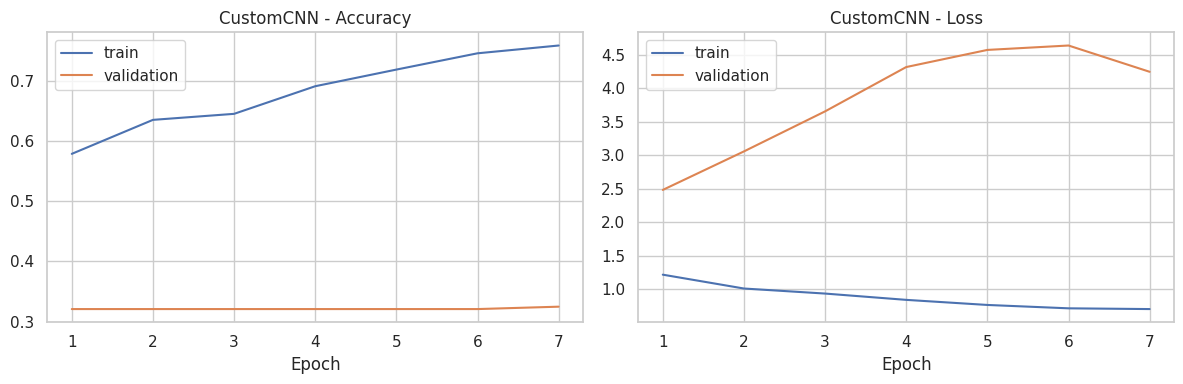

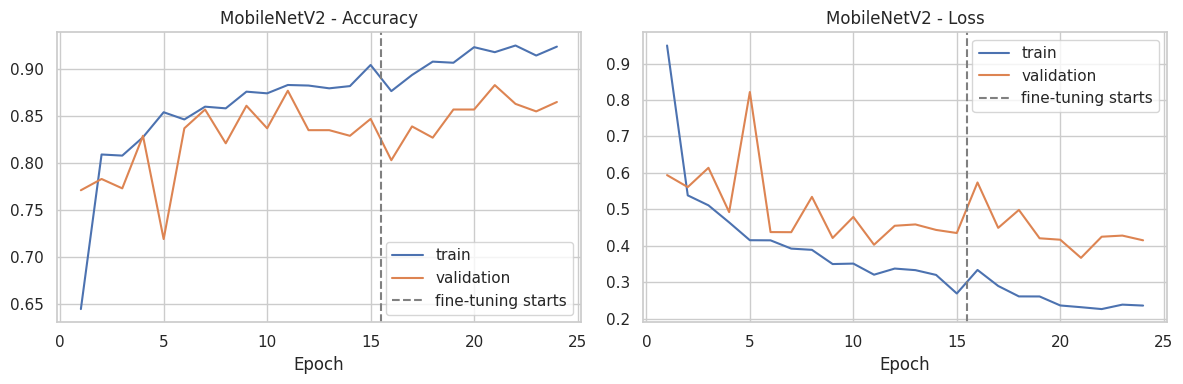

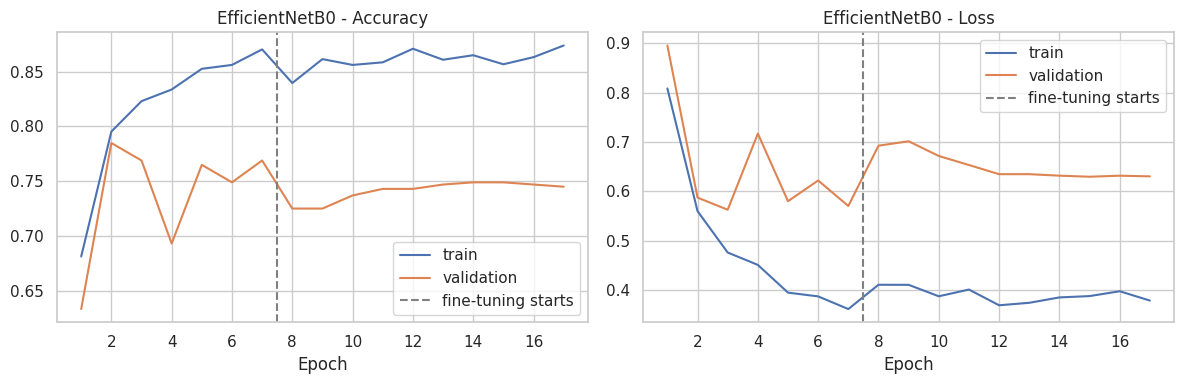

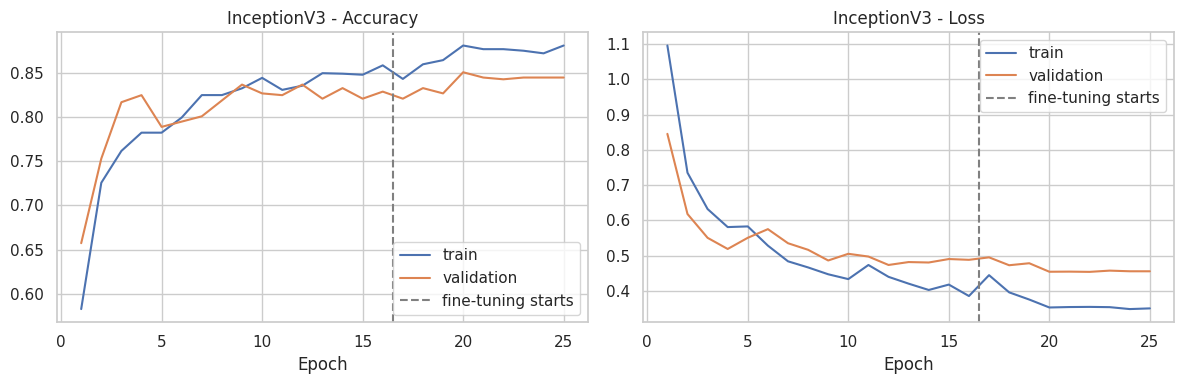

In [36]:
# Training curves for every model (dashed line = start of fine-tuning)
def plot_history(name):
    h = results[name]["history"]; split_at = results[name]["phase1_epochs"]
    ep = range(1, len(h["loss"]) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    for a, key, title in zip(ax, ["accuracy", "loss"], ["Accuracy", "Loss"]):
        a.plot(ep, h[key], label="train"); a.plot(ep, h["val_" + key], label="validation")
        if name != "CustomCNN" and len(h["loss"]) > split_at:
            a.axvline(split_at + 0.5, ls="--", c="gray", label="fine-tuning starts")
        a.set_title(f"{name} - {title}"); a.set_xlabel("Epoch"); a.legend()
    plt.tight_layout(); plt.show()

for n in results:
    plot_history(n)

**How to read these plots:** if training accuracy keeps rising while validation accuracy stalls or drops, the model is overfitting. The dashed line shows where fine-tuning begins; a small extra jump in validation accuracy after that line shows that fine-tuning helped.

### Metrics on validation & test sets

In [37]:
# Load the best saved weights (.h5) of every model and compute all metrics
loaded = {n: keras.models.load_model(os.path.join(MODEL_DIR, f"{n}.h5"), compile=False) for n in results}

def get_metrics(model, ds, d):
    t0 = time.time()
    probs = model.predict(ds, verbose=0)
    ms_per_img = (time.time() - t0) / len(d) * 1000
    y_true, y_pred = d["label_idx"].values, probs.argmax(1)
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    return {"accuracy": accuracy_score(y_true, y_pred), "precision": p, "recall": r, "f1": f,
            "ms_per_image": ms_per_img}, probs, y_pred

rows, test_probs, test_preds = [], {}, {}
for n, m in loaded.items():
    val_m, _, _ = get_metrics(m, val_ds, val_df)
    tst_m, probs, preds = get_metrics(m, test_ds, test_df)
    test_probs[n], test_preds[n] = probs, preds
    rows.append({"Model": n,
                 "Val Accuracy": val_m["accuracy"], "Val F1": val_m["f1"],
                 "Test Accuracy": tst_m["accuracy"], "Test Precision": tst_m["precision"],
                 "Test Recall": tst_m["recall"], "Test F1": tst_m["f1"],
                 "Params (M)": m.count_params() / 1e6,
                 "File Size (MB)": os.path.getsize(os.path.join(MODEL_DIR, f"{n}.h5")) / 1e6,
                 "ms / image": tst_m["ms_per_image"],
                 "Train time (min)": results[n]["train_time_min"]})

comparison = pd.DataFrame(rows).set_index("Model").round(4)
comparison

,Val Accuracy,Val F1,Test Accuracy,Test Precision,Test Recall,Test F1,Params (M),File Size (MB),ms / image,Train time (min)
Model,,,,,,,,,,
CustomCNN,0.3207,0.1214,0.3252,0.0813,0.2500,0.1227,1.2430,15.0624,2.0818,5.5451
MobileNetV2,0.8825,0.8786,0.8537,0.8603,0.8571,0.8535,2.5869,26.6727,1.9439,14.5671
EfficientNetB0,0.7550,0.7289,0.7642,0.7955,0.7528,0.7425,4.3785,20.6286,2.0504,11.0729
InceptionV3,0.8426,0.8338,0.8089,0.8175,0.8139,0.8058,22.3284,142.7178,2.7619,15.2865


### Confusion matrices

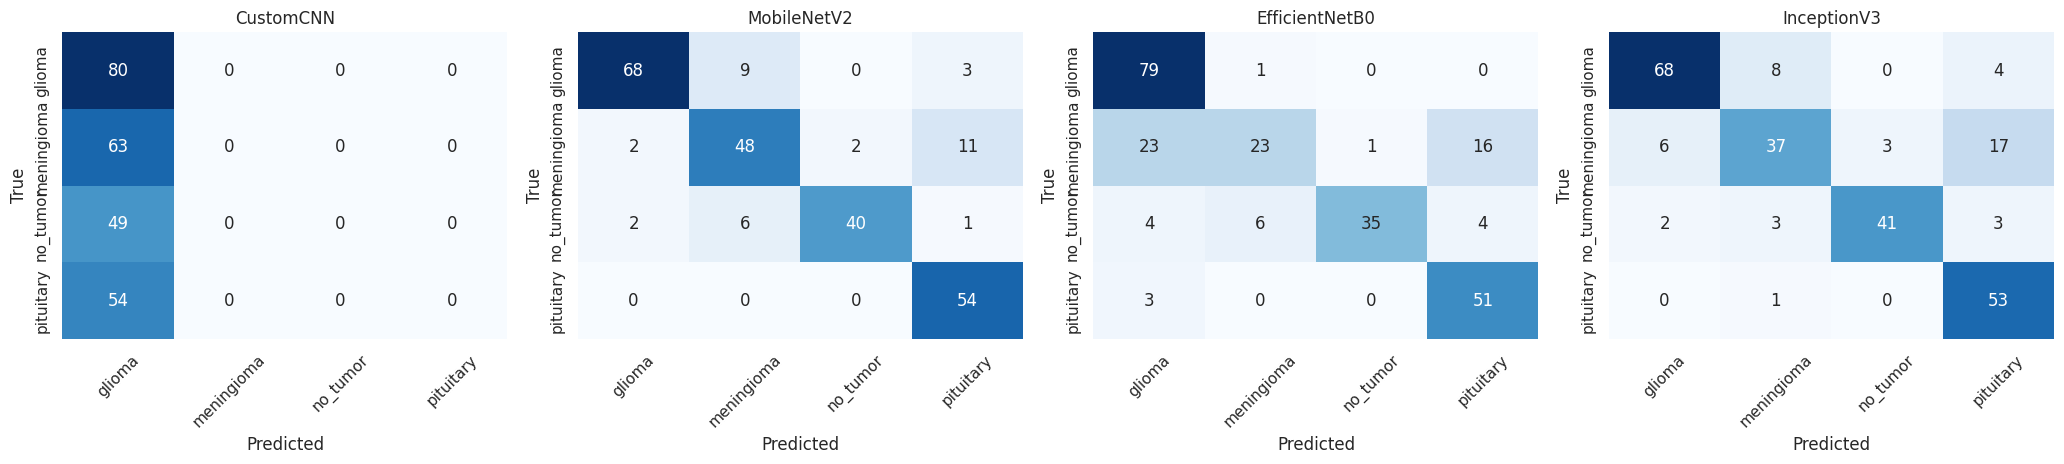

In [38]:
# Confusion matrix for every model (rows = true class, columns = predicted class)
n_models = len(loaded)
fig, axes = plt.subplots(1, n_models, figsize=(5.2 * n_models, 4.8))
axes = np.atleast_1d(axes)
for ax, n in zip(axes, loaded):
    cm = confusion_matrix(test_df["label_idx"].values, test_preds[n], labels=range(NUM_CLASSES))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=class_names, yticklabels=class_names)
    ax.set_title(n); ax.set_xlabel("Predicted"); ax.set_ylabel("True")
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

### Model comparison chart

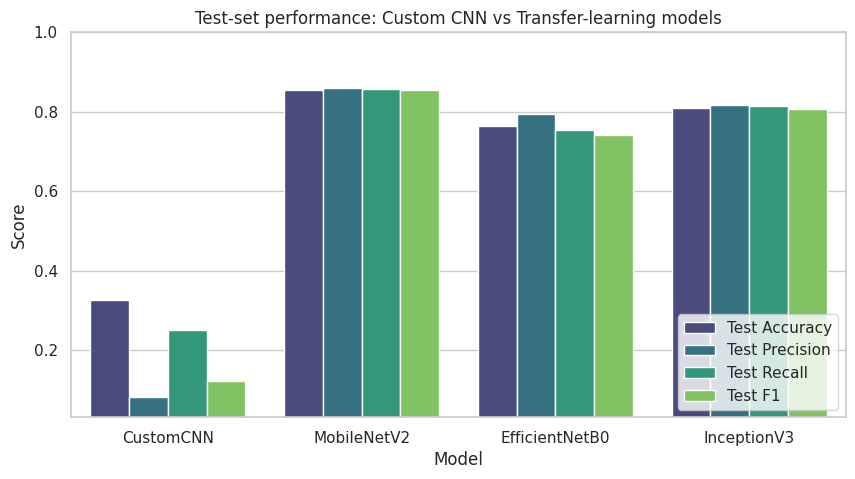

In [39]:
# Bar chart: custom CNN vs pretrained models
plot_df = comparison[["Test Accuracy", "Test Precision", "Test Recall", "Test F1"]].reset_index().melt(
    id_vars="Model", var_name="Metric", value_name="Score")
plt.figure(figsize=(10, 5))
ax = sns.barplot(data=plot_df, x="Model", y="Score", hue="Metric", palette="viridis")
ax.set_ylim(max(0, plot_df["Score"].min() - 0.05), 1.0)
plt.title("Test-set performance: Custom CNN vs Transfer-learning models")
plt.legend(loc="lower right"); plt.show()

### 1. Which evaluation metrics did you consider for a positive business impact and why?

* **Recall (per class) - the most important one.** In diagnosis support, a missed tumor (false negative) is far more harmful than a false alarm, because a missed case may be left without follow-up. High recall means that few tumors slip through.
* **Precision.** Low precision means many healthy / wrongly-typed scans are flagged, which wastes specialist time and worries patients. It must stay reasonable so the tool actually saves time.
* **F1-score (macro).** Balances precision and recall and treats all classes equally, so a big class cannot hide the failure on a small one. It is the main number used for model selection.
* **Accuracy.** Easy to communicate, but misleading when classes are imbalanced, so it is only a secondary metric.
* **Confusion matrix.** Shows *which* classes get confused with each other (for example two similar tumor types), which is where clinicians must be careful.
* **Inference time & model size.** Decide whether the model can run on an ordinary hospital computer in real time.

### 2. Which ML model did you choose as the final prediction model and why?

In [40]:
# Final model = best validation macro-F1 (selected on validation, NOT on test, to avoid test-set leakage).
# Ties are broken by the smaller model.
best_name = comparison.sort_values(["Val F1", "Params (M)"], ascending=[False, True]).index[0]
print("Selected model :", best_name)
print(comparison.loc[best_name].to_string())

print("\nPer-class report on the TEST set for", best_name)
print(classification_report(test_df["label_idx"].values, test_preds[best_name],
                            target_names=class_names, digits=4, zero_division=0))

Selected model : MobileNetV2
Val Accuracy         0.8825
Val F1               0.8786
Test Accuracy        0.8537
Test Precision       0.8603
Test Recall          0.8571
Test F1              0.8535
Params (M)           2.5869
File Size (MB)      26.6727
ms / image           1.9439
Train time (min)    14.5671

Per-class report on the TEST set for MobileNetV2
              precision    recall  f1-score   support

      glioma     0.9444    0.8500    0.8947        80
  meningioma     0.7619    0.7619    0.7619        63
    no_tumor     0.9524    0.8163    0.8791        49
   pituitary     0.7826    1.0000    0.8780        54

    accuracy                         0.8537       246
   macro avg     0.8603    0.8571    0.8535       246
weighted avg     0.8638    0.8537    0.8539       246



The model with the highest **validation macro-F1** is chosen (shown above). Selecting on the validation set - not on the test set - keeps the test result an unbiased estimate of real-world performance. If two models are practically equal, the smaller / faster one is preferred, because it is cheaper and easier to deploy. Compare the rows of the table above to see the trade-off between accuracy, size, speed and training time, and compare the pretrained models with the custom CNN to see how much transfer learning improved the result.

### 3. Explain the model used and the model explainability

36 wrong predictions out of 246 test images


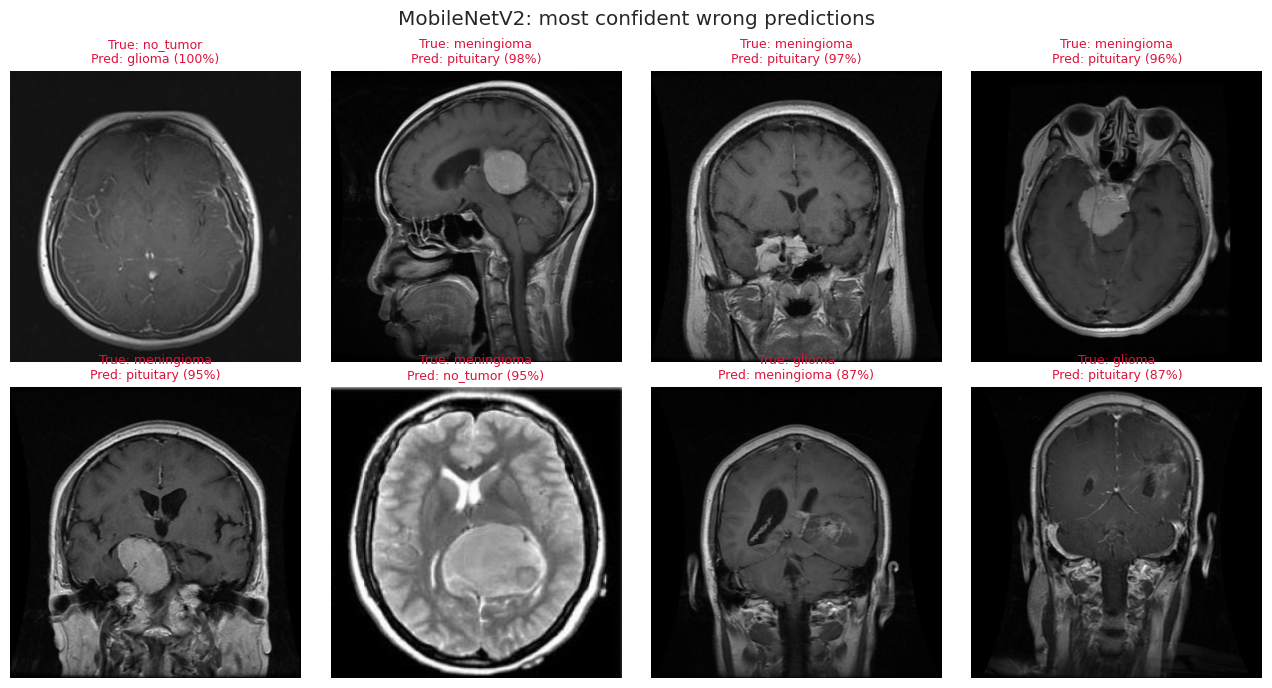

In [41]:
# Explainability (1): where does the final model go wrong? Show confident mistakes.
bm_probs, bm_preds = test_probs[best_name], test_preds[best_name]
wrong = np.where(bm_preds != test_df["label_idx"].values)[0]
print(f"{len(wrong)} wrong predictions out of {len(test_df)} test images")

if len(wrong):
    wrong = wrong[np.argsort(-bm_probs[wrong].max(1))][:8]          # most confident mistakes first
    fig, axes = plt.subplots(2, 4, figsize=(13, 7))
    for ax in axes.flat:
        ax.axis("off")
    for ax, i in zip(axes.flat, wrong):
        ax.imshow(Image.open(test_df.loc[i, "path"]).convert("L"), cmap="gray")
        ax.set_title(f"True: {class_names[test_df.loc[i, 'label_idx']]}\nPred: {class_names[bm_preds[i]]} ({bm_probs[i].max():.0%})",
                     fontsize=9, color="crimson")
    plt.suptitle(f"{best_name}: most confident wrong predictions"); plt.tight_layout(); plt.show()

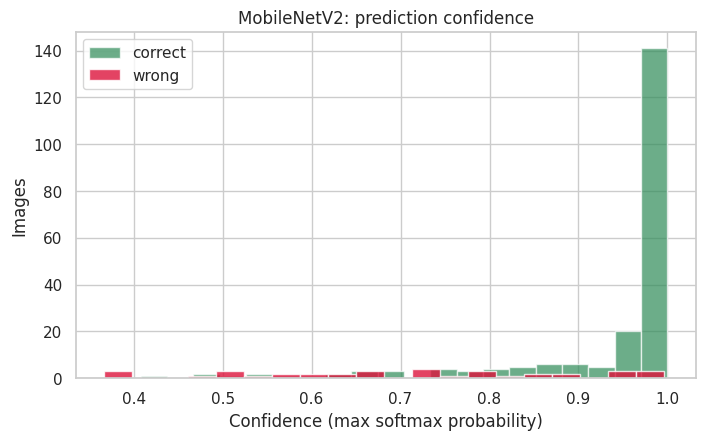

Mean confidence | correct: 0.937 | wrong: 0.707


In [42]:
# Explainability (2): is the confidence score trustworthy? Confidence of correct vs wrong predictions.
conf = bm_probs.max(1)
correct = bm_preds == test_df["label_idx"].values
plt.figure(figsize=(8, 4.5))
plt.hist(conf[correct], bins=20, alpha=0.7, label="correct", color="seagreen")
if (~correct).any():
    plt.hist(conf[~correct], bins=20, alpha=0.8, label="wrong", color="crimson")
plt.title(f"{best_name}: prediction confidence"); plt.xlabel("Confidence (max softmax probability)"); plt.ylabel("Images")
plt.legend(); plt.show()
print(f"Mean confidence | correct: {conf[correct].mean():.3f}" + (f" | wrong: {conf[~correct].mean():.3f}" if (~correct).any() else ""))

The final model is a CNN that turns an MRI image into one probability per class (softmax). Since a CNN is not a transparent model, we judge it with: (1) the **confusion matrix and per-class report** (which classes are confused), (2) the **most confident mistakes** (what kind of scans fool it), and (3) the **confidence histogram**: if wrong predictions mostly have *lower* confidence than correct ones, the confidence score shown in the app is a useful signal for 'please double-check this scan'. A natural next step is Grad-CAM heat-maps (see Future Work).

## ***8. Save the Model for Deployment***

### 1. Save the best performing model (.h5) and class names

In [43]:
# Save the best model as best_model.h5 + the class order used by the Streamlit app
best_path = os.path.join(MODEL_DIR, "best_model.h5")
shutil.copy(os.path.join(MODEL_DIR, f"{best_name}.h5"), best_path)
with open(os.path.join(MODEL_DIR, "class_names.json"), "w") as f:
    json.dump(class_names, f)
comparison.to_csv(os.path.join(MODEL_DIR, "model_comparison.csv"))

print("Saved models:", sorted(p for p in os.listdir(MODEL_DIR)))
print("Best model  :", best_name)

Saved models: ['CustomCNN.h5', 'EfficientNetB0.h5', 'InceptionV3.h5', 'MobileNetV2.h5', 'best_model.h5', 'class_names.json', 'model_comparison.csv']
Best model  : MobileNetV2


### 2. Load the saved model again and predict unseen data (sanity check)

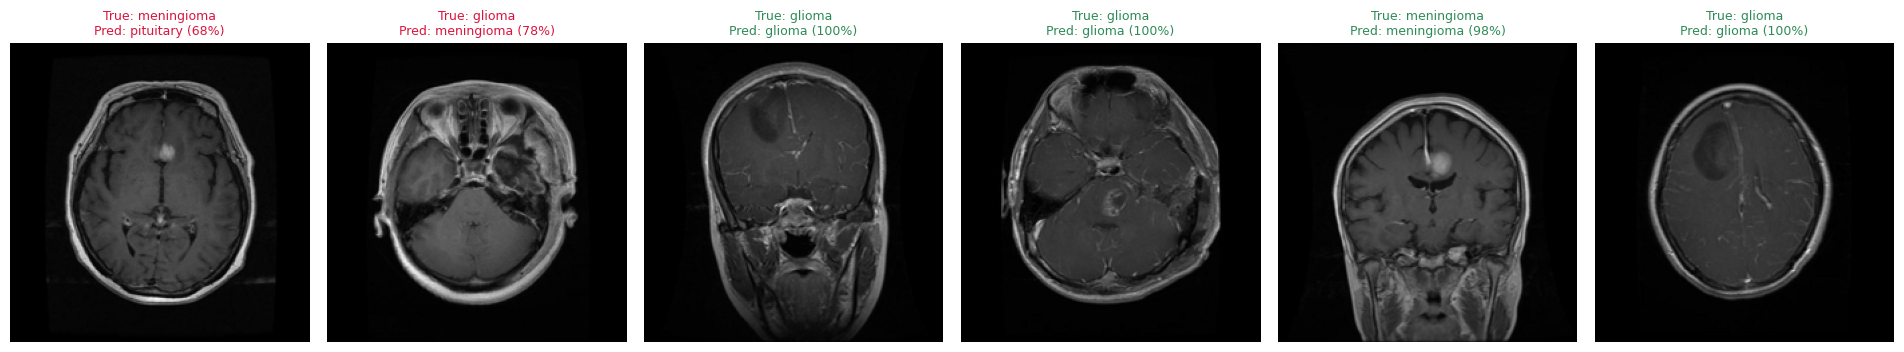

In [44]:
# Reload from disk and predict 6 random test images, exactly as the Streamlit app does
reloaded = keras.models.load_model(best_path, compile=False)
with open(os.path.join(MODEL_DIR, "class_names.json")) as f:
    names = json.load(f)

sample = test_df.sample(min(6, len(test_df)), random_state=1)
fig, axes = plt.subplots(1, len(sample), figsize=(3.2 * len(sample), 3.8))
axes = np.atleast_1d(axes)
for ax, (_, row) in zip(axes, sample.iterrows()):
    img = Image.open(row["path"]).convert("RGB").resize(IMG_SIZE)          # raw 0-255 pixels, no extra scaling needed
    probs = reloaded.predict(np.expand_dims(np.asarray(img, dtype="float32"), 0), verbose=0)[0]
    ok = names[probs.argmax()] == row["label"]
    ax.imshow(img); ax.axis("off")
    ax.set_title(f"True: {row['label']}\nPred: {names[probs.argmax()]} ({probs.max():.0%})",
                 fontsize=9, color="seagreen" if ok else "crimson")
plt.tight_layout(); plt.show()

### 3. Streamlit application
The web app is in **`app.py`**. Put `app.py` and the `models/` folder (with `best_model.h5`, the other `.h5` files and `class_names.json`) in the same directory and run:

```bash
pip install -r requirements.txt
streamlit run app.py
```

Users upload an MRI image, the app shows the predicted tumor type, the confidence and the probability of every class.

### ***Congrats! Your model is successfully created and ready for deployment on a live server for a real user interaction !!!***

## ***9. Future Work***

* Grad-CAM heat-maps to highlight the region of the MRI that drove each prediction.
* External validation on scans from a different hospital to confirm that the model generalises beyond this dataset.
* Test-time augmentation and an ensemble of the best two models for a further accuracy boost.
* Hyper-parameter search (Keras Tuner / Optuna) for learning rate, dropout and head size.
* Tumor segmentation (U-Net) in addition to classification.

# **Conclusion**

In [45]:
# Auto-generated final summary (numbers come from the run above)
b = comparison.loc[best_name]
cnn_f1 = comparison.loc["CustomCNN", "Test F1"] if "CustomCNN" in comparison.index else float("nan")
print(f"Classes ({NUM_CLASSES}): {class_names}")
print(f"Final model          : {best_name}")
print(f"Test accuracy        : {b['Test Accuracy']:.2%}")
print(f"Test macro precision : {b['Test Precision']:.2%} | recall: {b['Test Recall']:.2%} | F1: {b['Test F1']:.2%}")
print(f"Custom CNN test F1   : {cnn_f1:.2%}  ->  gain of the final model over the baseline: {b['Test F1'] - cnn_f1:+.2%}")
print(f"Model size / speed   : {b['File Size (MB)']:.1f} MB, {b['ms / image']:.1f} ms per image")

Classes (4): ['glioma', 'meningioma', 'no_tumor', 'pituitary']
Final model          : MobileNetV2
Test accuracy        : 85.37%
Test macro precision : 86.03% | recall: 85.71% | F1: 85.35%
Custom CNN test F1   : 12.27%  ->  gain of the final model over the baseline: +73.08%
Model size / speed   : 26.7 MB, 1.9 ms per image


In [46]:
   !zip -r models.zip models
   from google.colab import files
   files.download("models.zip")

  adding: models/ (stored 0%)
  adding: models/best_model.h5 (deflated 9%)
  adding: models/class_names.json (deflated 14%)
  adding: models/model_comparison.csv (deflated 36%)
  adding: models/MobileNetV2.h5 (deflated 9%)
  adding: models/CustomCNN.h5 (deflated 9%)
  adding: models/InceptionV3.h5 (deflated 8%)
  adding: models/EfficientNetB0.h5 (deflated 9%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In this project a complete deep-learning pipeline for brain-MRI classification was built: the dataset was audited (corrupt files, duplicates, leakage, class balance, resolution), preprocessed and augmented; a **custom CNN** was trained from scratch and compared with three **transfer-learning models** (MobileNetV2, EfficientNetB0, InceptionV3) using accuracy, precision, recall, F1, confusion matrices and training curves. The final model was selected on validation macro-F1, saved as `best_model.h5`, reloaded for a sanity check, and exposed through a Streamlit app that returns the tumor type with a confidence score.

**Business value:** the tool can shorten the time a radiologist needs for a first read, flag scans for priority review, and provide a second opinion in under-resourced regions. **Limitations:** it was trained on one public dataset, so it must be validated on local hospital data before any real use, and it is a decision-support aid, never a replacement for a doctor's diagnosis.

### ***Hurrah! You have successfully completed your Machine Learning Capstone Project !!!***